In [ ]:
4.5: Two Images - Magnitude and Phase

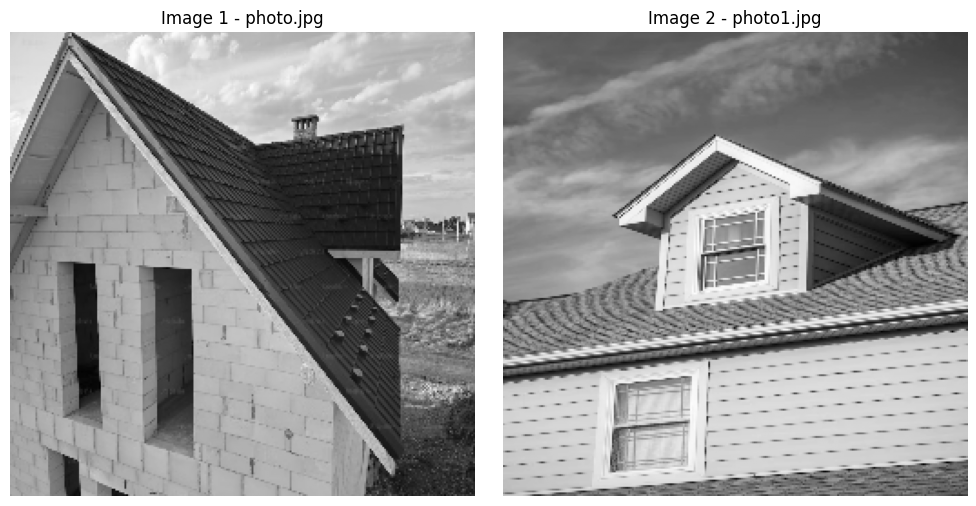

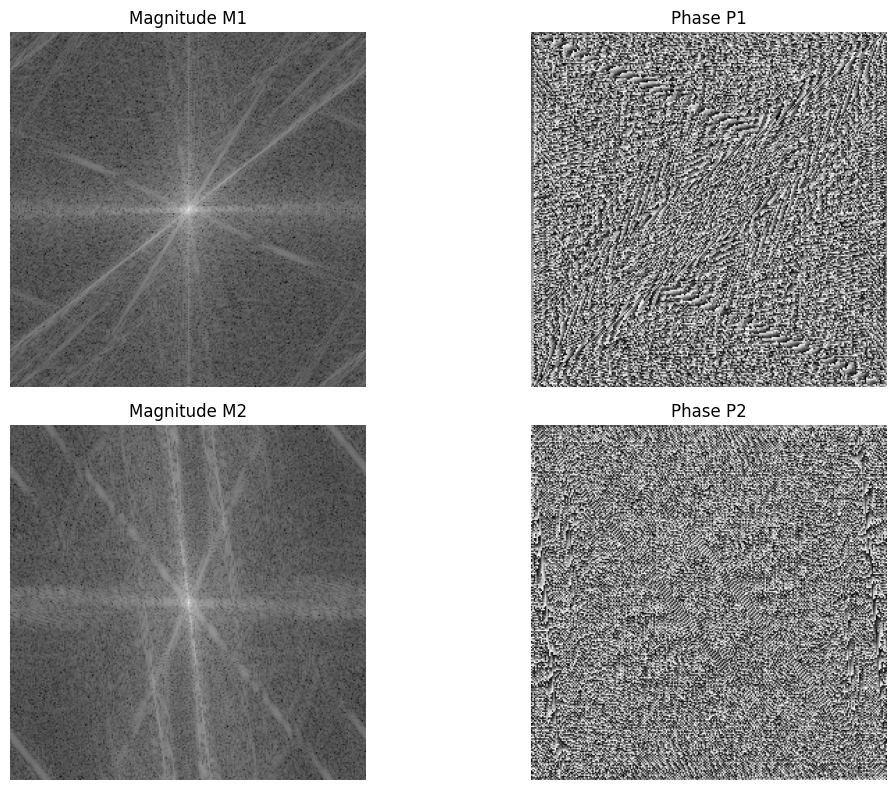

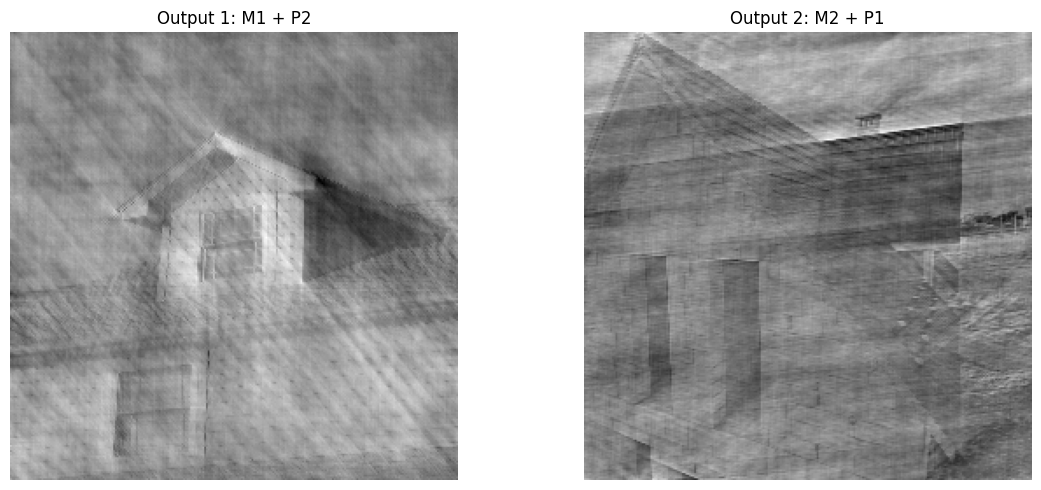

Assignment 4.5 Completed Successfully!
Output 1: M1 + P2 saved.
Output 2: M2 + P1 saved.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load Two Images
img1 = cv2.imread('/content/photo.jpg', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('/content/photo1.jpg', cv2.IMREAD_GRAYSCALE)

# Check Images
if img1 is None:
    raise FileNotFoundError("photo.jpg not found!")

if img2 is None:
    raise FileNotFoundError("photo1.jpg not found!")

# Step 2: Resize Both Images
img1 = cv2.resize(img1, (256, 256))
img2 = cv2.resize(img2, (256, 256))

# Step 3: Apply Fourier Transform
F1 = np.fft.fft2(img1)
F2 = np.fft.fft2(img2)

# Step 4: Calculate Magnitude and Phase
M1 = np.abs(F1)
P1 = np.angle(F1)

M2 = np.abs(F2)
P2 = np.angle(F2)

# Step 5: Swap Magnitude and Phase

# Image 1 Magnitude + Image 2 Phase
F_M1_P2 = M1 * np.exp(1j * P2)

# Image 2 Magnitude + Image 1 Phase
F_M2_P1 = M2 * np.exp(1j * P1)

# Step 6: Apply Inverse Fourier Transform
IFFT1 = np.fft.ifft2(F_M1_P2)
IFFT2 = np.fft.ifft2(F_M2_P1)

# Step 7: Convert to Real Images
output1 = np.real(IFFT1)
output2 = np.real(IFFT2)

# Step 8: Normalize Images
output1 = cv2.normalize(
    output1, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

output2 = cv2.normalize(
    output2, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Step 9: Display Original Images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap='gray')
plt.title("Image 1 - photo.jpg")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap='gray')
plt.title("Image 2 - photo1.jpg")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 10: Display Magnitude and Phase
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(np.log1p(np.fft.fftshift(M1)), cmap='gray')
plt.title("Magnitude M1")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(P1, cmap='gray')
plt.title("Phase P1")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(np.log1p(np.fft.fftshift(M2)), cmap='gray')
plt.title("Magnitude M2")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(P2, cmap='gray')
plt.title("Phase P2")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 11: Display Final IFFT Results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(output1, cmap='gray')
plt.title("Output 1: M1 + P2")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(output2, cmap='gray')
plt.title("Output 2: M2 + P1")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 12: Save Output Images
cv2.imwrite(
    '/content/Assignment_4_5_Output1_M1_P2.png',
    output1
)

cv2.imwrite(
    '/content/Assignment_4_5_Output2_M2_P1.png',
    output2
)

print("Assignment 4.5 Completed Successfully!")
print("Output 1: M1 + P2 saved.")
print("Output 2: M2 + P1 saved.")